# 02 · Approach A: hand-crafted pose features + classic machine learning

**Idea:** shoplifting is mostly about what the **hands** do relative to the **body**: reaching, then moving an item to a pocket, waistband or bag, often while crouching or turned away. We measure these things directly from the keypoints and let standard classifiers learn which ones matter.

Steps for every clip:
1. take the **primary person** (the person tracked for the longest);
2. **normalise** the pose: put the mid-hip at (0, 0) and measure everything in **torso lengths**, so camera resolution and distance do not matter. Joints that are **never** visible in a clip (for example ankles cut off by the frame) are set to 0, the body centre, so they carry no information about where the person stood in the image;
3. compute **21 measurements per frame** (wrist-to-hip distances, elbow/knee angles, torso lean, crouch, hand speed, hand visibility, number of people, ...);
4. summarise each over the clip with **6 statistics** (mean, std, min, max, 10th and 90th percentile), plus the fraction of time a hand is near the hip/pocket. This gives **127 features per clip**.

Then three classifiers are tuned with 5-fold cross-validation on the training set and compared on the validation set. The test set is **not** used here.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import pose_utils as pu

manifest = pu.load_manifest()

## 1. Build one feature row per clip

In [2]:
X_all = pd.DataFrame([pu.clip_features(pu.clip_to_sequence(pu.load_extraction(p))) for p in manifest["cache_path"]])
feature_names = list(X_all.columns)
meta_cols = ["relative_path", "label", "label_name", "source", "split"]
features = pd.concat([manifest[meta_cols].reset_index(drop=True), X_all], axis=1)
features.to_csv(pu.RESULTS_DIR / "clip_features.csv", index=False)
print(f"{features.shape[0]} clips x {len(feature_names)} features")
features.head()

207 clips x 127 features


,relative_path,label,label_name,source,split,lwrist_lhip_mean,rwrist_rhip_mean,lwrist_midhip_mean,rwrist_midhip_mean,lwrist_nose_mean,...,rknee_angle_p90,torso_lean_p90,crouch_p90,lwrist_speed_p90,rwrist_speed_p90,body_speed_p90,lwrist_visible_p90,rwrist_visible_p90,n_people_p90,hand_near_hip_frac
0,videos/shoplifting/Shoplifting001_x264.mp4,1,shoplifting,dcsass,train,0.476862,0.797532,0.500488,0.839407,0.971146,...,168.195435,38.171234,1.282064e+00,0.071556,0.069574,0.072695,0.0,1.0,2.0,0.467969
1,videos/shoplifting/Shoplifting005_x264.mp4,1,shoplifting,dcsass,test,0.482376,0.479930,0.530961,0.507230,0.632985,...,178.761230,3.461404,1.447256e+00,0.106497,0.124829,0.092246,1.0,1.0,2.0,0.528125
2,videos/shoplifting/Shoplifting006_x264.mp4,1,shoplifting,dcsass,train,0.580519,0.552662,0.499255,0.633365,1.479530,...,6.856606,77.217514,1.415610e-07,0.048642,0.055176,0.036067,1.0,1.0,4.0,0.770833
3,videos/shoplifting/Shoplifting007_x264.mp4,1,shoplifting,dcsass,train,0.428976,0.660390,0.398925,0.742170,0.991229,...,132.692334,9.265731,8.012619e-01,0.040402,0.057442,0.044182,1.0,1.0,4.0,0.844375
4,videos/shoplifting/Shoplifting009_x264.mp4,1,shoplifting,dcsass,train,0.585614,0.799802,0.731637,0.718300,0.385052,...,179.862946,55.604351,8.088577e-01,0.171700,0.149205,0.099609,1.0,1.0,4.0,0.228750


### What a feature looks like over time

Distance from each wrist to the same-side hip, in torso lengths, for one normal and one shoplifting clip. The dashed line is the "hand near hip/pocket" threshold.

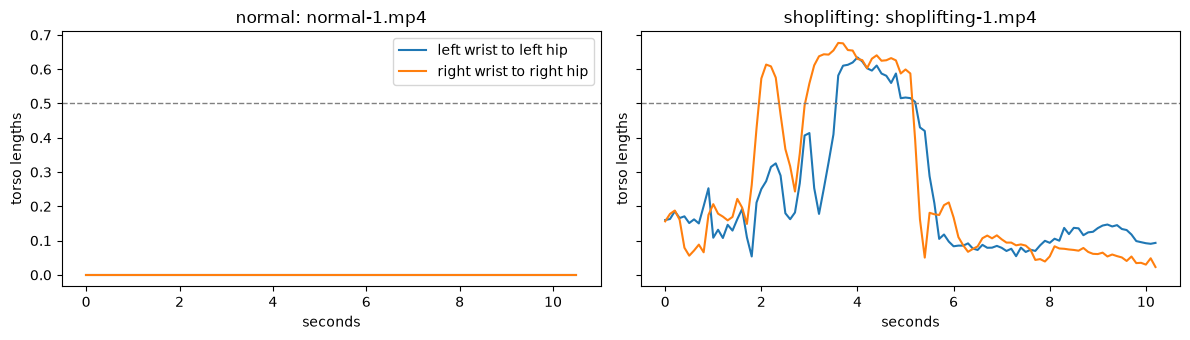

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, label in zip(axes, ["normal", "shoplifting"]):
    row = manifest[(manifest.source == "staged") & (manifest.label_name == label) & (manifest.split == "train")].iloc[0]
    ff = pu.frame_features(pu.clip_to_sequence(pu.load_extraction(row.cache_path)))
    t = np.arange(len(ff)) / pu.TARGET_FPS
    ax.plot(t, ff["lwrist_lhip"], label="left wrist to left hip")
    ax.plot(t, ff["rwrist_rhip"], label="right wrist to right hip")
    ax.axhline(pu.NEAR_HIP, ls="--", c="grey", lw=1)
    ax.set(title=f"{label}: {Path(row.relative_path).name}", xlabel="seconds", ylabel="torso lengths")
axes[0].legend()
plt.tight_layout()
plt.savefig(pu.FIGURES_DIR / "02_wrist_hip_timeline.png", dpi=150)
plt.show()

## 2. Train and compare three classifiers

- **Logistic Regression**: a linear baseline (features standardised first).
- **Random Forest**: many decision trees voting; robust on small data.
- **Histogram Gradient Boosting**: trees built one after another, each fixing the previous ones' mistakes.

All use `class_weight="balanced"` (116 shoplifting vs 91 normal clips). Hyperparameters are chosen by 5-fold stratified cross-validation on **train** (scored by F1), and models are then compared on **validation**.

In [4]:
train = features[features.split == "train"]
val = features[features.split == "validation"]
X_train, y_train = train[feature_names], train["label"]
X_val, y_val = val[feature_names], val["label"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=pu.SEED)

candidates = {
    "LogisticRegression": (
        make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=5000)),
        {"logisticregression__C": [0.01, 0.1, 1, 10]},
    ),
    "RandomForest": (
        RandomForestClassifier(n_estimators=500, class_weight="balanced", random_state=pu.SEED, n_jobs=-1),
        {"max_depth": [None, 5, 10], "min_samples_leaf": [1, 3, 5], "max_features": ["sqrt", 0.3]},
    ),
    "HistGradientBoosting": (
        HistGradientBoostingClassifier(class_weight="balanced", random_state=pu.SEED),
        {"learning_rate": [0.05, 0.1], "max_depth": [3, None], "max_iter": [100, 300], "l2_regularization": [0.0, 1.0]},
    ),
}
rows, fitted = [], {}
for name, (estimator, grid) in candidates.items():
    # n_jobs=1: joblib's worker processes crash intermittently on Windows ("handle is invalid");
    # Random Forest and Gradient Boosting still use all CPU cores internally via threads.
    search = GridSearchCV(estimator, grid, scoring="f1", cv=cv, n_jobs=1)
    search.fit(X_train, y_train)
    p_val = search.best_estimator_.predict_proba(X_val)[:, 1]
    rows.append({"model": name, "cv_f1": search.best_score_,
                 "val_f1": f1_score(y_val, p_val >= 0.5), "val_auc": roc_auc_score(y_val, p_val),
                 "val_acc": accuracy_score(y_val, p_val >= 0.5), "best_params": search.best_params_})
    fitted[name] = search.best_estimator_
    print(f"{name:22s} cv_f1={search.best_score_:.3f}  val_f1={rows[-1]['val_f1']:.3f}  val_auc={rows[-1]['val_auc']:.3f}")
comparison = pd.DataFrame(rows).sort_values(["val_f1", "val_auc"], ascending=False).reset_index(drop=True)
comparison.drop(columns="best_params").to_csv(pu.RESULTS_DIR / "approach_a_model_comparison.csv", index=False)
comparison

LogisticRegression     cv_f1=0.761  val_f1=0.625  val_auc=0.620


RandomForest           cv_f1=0.764  val_f1=0.765  val_auc=0.774


HistGradientBoosting   cv_f1=0.794  val_f1=0.914  val_auc=0.873


,model,cv_f1,val_f1,val_auc,val_acc,best_params
0,HistGradientBoosting,0.793558,0.914286,0.873303,0.900000,"{'l2_regularization': 0.0, 'learning_rate': 0...."
1,RandomForest,0.764145,0.764706,0.773756,0.733333,"{'max_depth': None, 'max_features': 'sqrt', 'm..."
2,LogisticRegression,0.761439,0.625000,0.619910,0.600000,{'logisticregression__C': 10}


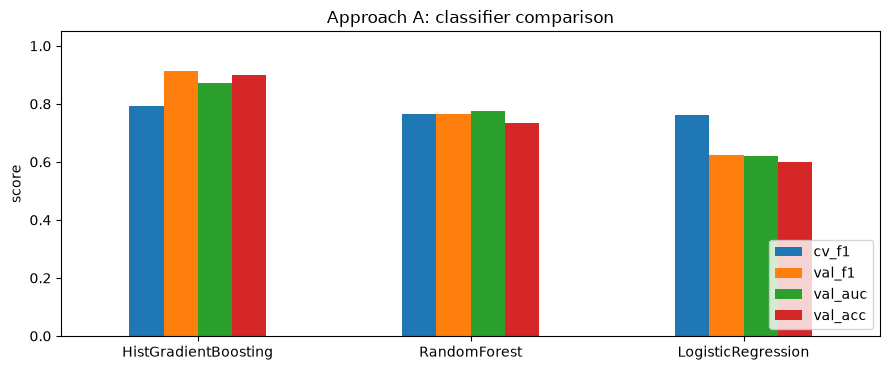

In [5]:
ax = comparison.set_index("model")[["cv_f1", "val_f1", "val_auc", "val_acc"]].plot.bar(rot=0, figsize=(9, 3.8), ylim=(0, 1.05))
ax.set(title="Approach A: classifier comparison", ylabel="score", xlabel="")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(pu.FIGURES_DIR / "02_model_comparison.png", dpi=150)
plt.show()

## 3. Save the best model (chosen on validation F1, ties broken by ROC-AUC)

In [6]:
best = comparison.iloc[0]
best_model = fitted[best["model"]]
joblib.dump(best_model, pu.MODELS_DIR / "approach_a.joblib")
meta = {"model": best["model"], "feature_names": feature_names,
        "cv_f1": float(best["cv_f1"]), "val_f1": float(best["val_f1"]),
        "val_auc": float(best["val_auc"]), "val_acc": float(best["val_acc"]),
        "best_params": best["best_params"]}
(pu.MODELS_DIR / "approach_a_meta.json").write_text(json.dumps(meta, indent=2, default=str))
print("Saved", best["model"], "with params", best["best_params"])

Saved HistGradientBoosting with params {'l2_regularization': 0.0, 'learning_rate': 0.1, 'max_depth': 3, 'max_iter': 300}


## 4. Which features matter?

**Permutation importance** on the validation set: shuffle one feature at a time and measure how much ROC-AUC drops. A bigger drop means the model relies on that feature more.

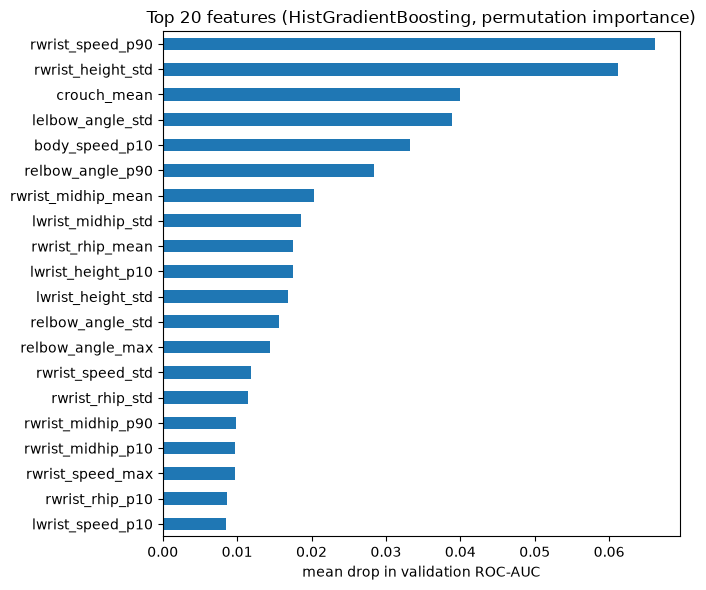

In [7]:
imp = permutation_importance(best_model, X_val, y_val, scoring="roc_auc", n_repeats=30, random_state=pu.SEED, n_jobs=1)
importance = pd.Series(imp.importances_mean, index=feature_names).sort_values(ascending=False)
importance.to_csv(pu.RESULTS_DIR / "approach_a_feature_importance.csv", header=["importance"])
ax = importance.head(20)[::-1].plot.barh(figsize=(7, 6))
ax.set(title=f"Top 20 features ({best['model']}, permutation importance)", xlabel="mean drop in validation ROC-AUC")
plt.tight_layout()
plt.savefig(pu.FIGURES_DIR / "02_feature_importance.png", dpi=150)
plt.show()

### Do the top features measure behaviour or tracking quality?

When the primary person is not tracked in a frame, their pose is filled in from neighbouring frames, so speeds in those frames read as 0 or constant. A feature can therefore partly measure **how often the person was tracked** rather than how they moved. Below: the Spearman correlation between each top feature and the clip's tracking coverage (`primary_rate` from notebook 01). Features with |ρ| above about 0.5 should be described with this caveat in the report.

In [8]:
from scipy.stats import spearmanr

quality = pd.read_csv(pu.RESULTS_DIR / "pose_quality.csv").set_index("relative_path")
coverage = features["relative_path"].map(quality["primary_rate"])
has_person = coverage > 0
coverage_check = pd.DataFrame(
    [{"feature": f, "importance": importance[f],
      "spearman_rho_with_coverage": spearmanr(features.loc[has_person, f], coverage[has_person])[0]}
     for f in importance.head(10).index]
).round(3)
coverage_check.to_csv(pu.RESULTS_DIR / "approach_a_coverage_check.csv", index=False)
coverage_check

,feature,importance,spearman_rho_with_coverage
0,rwrist_speed_p90,0.066,-0.206
1,rwrist_height_std,0.061,-0.180
2,crouch_mean,0.040,0.312
3,lelbow_angle_std,0.039,-0.158
4,body_speed_p10,0.033,0.585
5,relbow_angle_p90,0.028,-0.234
6,rwrist_midhip_mean,0.020,-0.212
7,lwrist_midhip_std,0.019,-0.252
8,rwrist_rhip_mean,0.017,-0.082
9,lwrist_height_p10,0.017,0.143


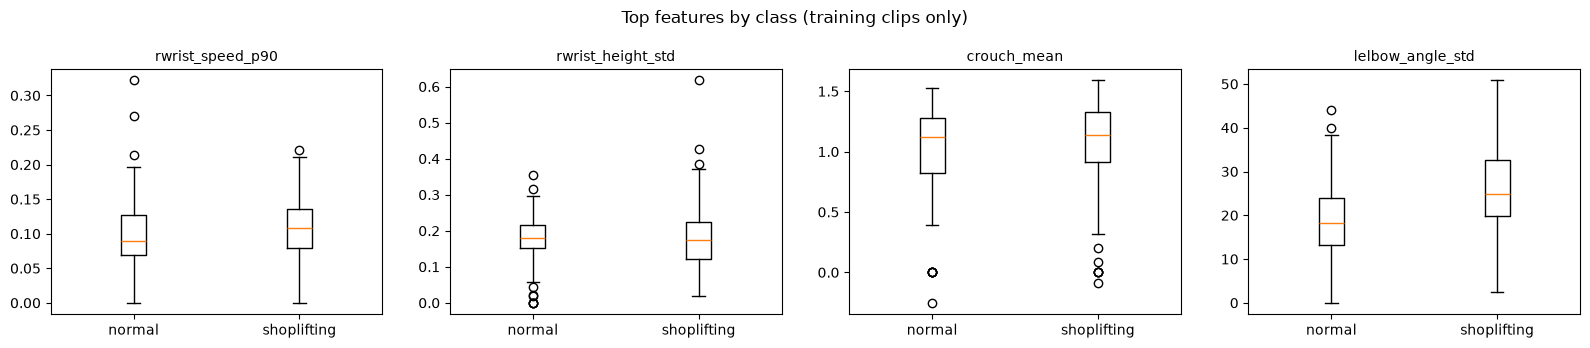

In [9]:
top = list(importance.head(4).index)
fig, axes = plt.subplots(1, len(top), figsize=(4 * len(top), 3.5))
for ax, f in zip(axes, top):
    data = [train.loc[train.label_name == lbl, f] for lbl in ["normal", "shoplifting"]]
    ax.boxplot(data, tick_labels=["normal", "shoplifting"])
    ax.set_title(f, fontsize=10)
plt.suptitle("Top features by class (training clips only)")
plt.tight_layout()
plt.savefig(pu.FIGURES_DIR / "02_top_features_by_class.png", dpi=150)
plt.show()